# Plot dark matter spectra
This notebook describes how to generate DM annihilation spectra with `gammapy`. Display DM spectra using `gammapy` and the PPPC models from M.Cirelli, G.Corcella, A.Hektor, G.Hütsi, M.Kadastik, P.Panci, M.Raidal, F.Sala, A.Strumia, "PPPC 4 DM ID: A Poor Particle Physicist Cookbook for Dark Matter Indirect Detection'', arXiv 1012.4515, JCAP 1103 (2011) 051. Erratum: JCAP 1210 (2012) E01.

Authors:  Michele Doro michele.doro@unipd.it

Last update: 2025.07.21

#### General imports

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
%matplotlib inline

In [7]:
from gammapy.astro.darkmatter import (
    profiles,
    JFactory,
    PrimaryFlux,
    DarkMatterAnnihilationSpectralModel,
)

# Plot image

### Version 1: dnde *E2

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
mDMs = [0.5, 5, 50] * u.TeV

labels = [r'$b\bar{b}$', r'$\tau^+\tau^-$', r'$W^+W^-$', r'$\mu^+\mu^-$']
linestyles = ['-', '--', 'dotted', 'dashdot']
linewidths = [2, 2, 1, 1]
colors = ['tab:blue', 'tab:orange', 'black', 'black']
channels = ["b", "tau", "W", "mu"]

for mDM, ax in zip(mDMs, axes):
    ax.set_title(rf"$m_{{\mathrm{{DM}}}}$ = {mDM:.0f}")
    ax.set_yscale("log")
    ax.set_xlim(mDM.to_value() / 100, mDM.to_value())

    for channel, label, linestyle, linewidth, color in zip(channels, labels, linestyles, linewidths, colors):
        fluxes = PrimaryFlux(mDM=mDM, channel=channel)

        fluxes.plot(
            energy_bounds=[mDM / 100, mDM],
            ax=ax,
            label=label,
            linestyle=linestyle,
            linewidth=linewidth,
            color=color,
            yunits=u.Unit("TeV"),
            sed_type="e2dnde",
        )

axes[0].legend()


## Version2: dnde * E2/mass

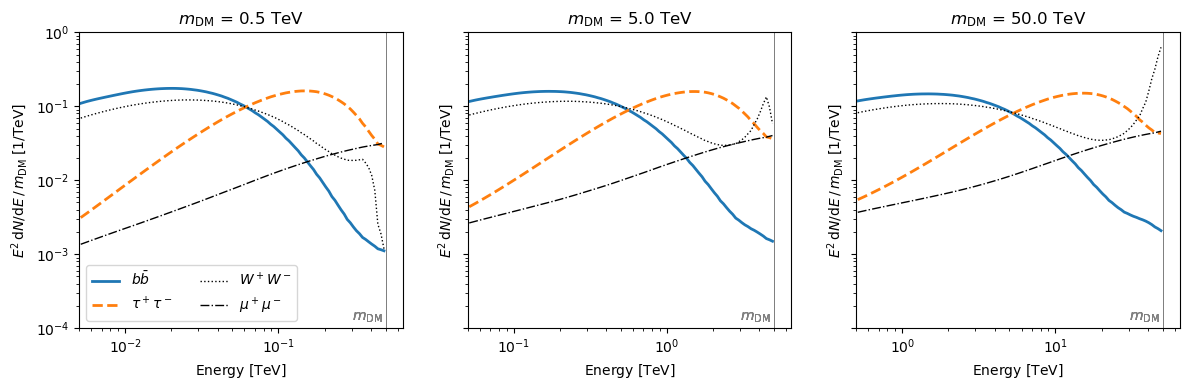

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
mDMs = [0.5, 5, 50] * u.TeV

labels = [r'$b\bar{b}$', r'$\tau^+\tau^-$', r'$W^+W^-$', r'$\mu^+\mu^-$']
linestyles = ['-', '--', 'dotted', 'dashdot']
linewidths = [2, 2, 1, 1]
colors = ['tab:blue', 'tab:orange', 'black', 'black']
channels = ["b", "tau", "W", "mu"]

for mDM, ax in zip(mDMs, axes):
    ax.set_title(rf"$m_{{\mathrm{{DM}}}}$ = {mDM:.1f}")
    ax.set_yscale("log")
    ax.set_xlim(mDM.to_value() / 100, mDM.to_value()*1.3)

    for channel, label, linestyle, linewidth, color in zip(channels, labels, linestyles, linewidths, colors):
        fluxes = PrimaryFlux(mDM=mDM, channel=channel)

        # Record number of existing lines before plotting
        n_lines_before = len(ax.lines)

        # Plot the spectrum
        fluxes.plot(
            energy_bounds=[mDM / 100, mDM],
            ax=ax,
            label=None,
            linestyle=linestyle,
            linewidth=linewidth,
            color=color,
            yunits=u.Unit("TeV"),
            sed_type="e2dnde",
        )

        # Get the most recent line added to the axis
        new_line = ax.lines[-1]

        # Rescale y-data by mDM
        xdata = new_line.get_xdata()
        ydata = new_line.get_ydata()
        yscaled = ydata / mDM.to_value("TeV")
        new_line.set_ydata(yscaled)
        new_line.set_label(label)

        # Add vertical line at mDM
        ax.axvline(mDM.to_value("TeV"), color="gray", linestyle="-", linewidth=0.5)

        # Add text label near the bottom-left of the vertical line
        ax.text(
        mDM.to_value("TeV") * 0.95,   # slightly to the left of the line
            1.1e-4,                       # just above the bottom y-limit
            r"$m_{\rm DM}$",
            ha="right", va="bottom", fontsize=10, color="gray"
)


for ax in axes:
    ax.set_ylim(1e-4, 1e0)
    ax.set_ylabel(r"$E^2\,\mathrm{d}N/\mathrm{d}E \,/\, m_{\rm DM}$ [1/TeV]")

axes[0].legend(ncols=2, loc="lower left")
#axes[0].set_ylabel(r"$E^2\,\mathrm{d}N/\mathrm{d}E \,/\, m_{\rm DM}$ [1/TeV]")

plt.tight_layout()
plt.subplots_adjust(wspace=0.2)


plt.savefig("plot_dm_spectra.png", dpi=300, bbox_inches="tight")
plt.show()
